# 08. Cross-Institution Consortium Fraud Exchange & Confidential Credit (`Morpho / RWA`)

Copyright 2026 Blind Labs (https://blindlabs.ai). Licensed under the Apache License, Version 2.0.

## Executive Summary (For VCs, Grant Reviewers & Executives)

### What problem does this solve?
Banks, RWA credit desks, and DeFi lending protocols (`Morpho` vaults) lose billions annually
to repeat borrowers and multi-venue fraud rings that exploit data silos. Competing
institutions cannot pool raw borrower tables into a shared data lake without violating
GDPR, GLBA, trade-secret covenants, and antitrust boundaries.

### Why can't AWS, legacy FHE, or hardware TEEs do this?
- **Standard Cloud Clean Rooms (AWS / Snowflake)**: Hold plaintext borrower identities and
  leverage ratios in shared compute memory; a single breach or insider exposes all three
  banks' customer books, and GDPR "Right to Erasure" requires expensive `O(N)` table rewrites.
- **Legacy General-Purpose FHE**: Joint fraud classification plus encrypted `<= 3.0x`
  leverage covenant checks across pooled cohorts run too slowly for real-time loan underwriting.
- **Hardware TEEs**: Compliance officers in regulated financial consortia reject single-vendor
  enclave trust assumptions and side-channel exposure of individual borrower records.
- **BlindCore**: Pools encrypted borrower records from **3 competing institutions**, runs
  encrypted `SKLEARN_MNB` fraud scoring + `RANGE_GATE` (`<= 3.0x` leverage covenant) on
  Base `x402 v2`, enforces a hard **`k_min_tkms = 5` singleton privacy guard** (blocking
  attempts to isolate a single borrower with `HTTP 422` and zero payment settlement), and
  delivers **`O(1)` cryptographic shredding** (single-key drop renders a borrower's historical
  ciphertexts permanently undecryptable without rewriting tables).

### End-to-End Architecture

```text
+-------------------+   +-------------------+   +-------------------+
| Institution A     |   | Institution B     |   | Institution C     |
| (Prime RWA Desk)  |   | (Morpho Vault)    |   | (Card / Bank)     |
+---------+---------+   +---------+---------+   +---------+---------+
          | Encrypted rows        | Encrypted rows        | Encrypted rows
          +-----------------------+-----------------------+
                                  |  Base x402 v2 USDC
                                  v
                    +---------------------------+
                    | BlindCore Tri-Rail Gate   |
                    |  * x402 replay block: 402 |
                    |  * Singleton k<5: HTTP 422| -> Settlement ABORTED ($0 charged)
                    +-------------+-------------+
                                  |
                                  v
                    +---------------------------+
                    | BlindCore Compute Engine  |
                    |  * SKLEARN_MNB fraud gate | -> PRIME_APPROVE / FRAUD_FLAG_DECLINE
                    |  * RANGE_GATE <= 3.0x lev | -> COVENANT_PASS / COVENANT_BREACH
                    |  * O(1) Crypto-Shredding  | -> Instant GDPR Right-to-Erasure
                    +-------------+-------------+
                                  |
                                  v
                    +---------------------------+
                    | Base L2 EIP-712 v2 Proof  |
                    | + 96 B NSAU0001 Receipt   |
                    +---------------------------+
```


In [1]:
import base64
import json
import urllib.error
import urllib.request

GATE_URL = "https://api.blindlabs.ai/testnet"
PROBE_PATH = "/api/v1/blind/jsonb/query"
PROBE_PAYLOAD = {"op": "SKLEARN_MNB", "table": "tbl_consortium_credit_probe"}

req = urllib.request.Request(
    GATE_URL + PROBE_PATH,
    data=json.dumps(PROBE_PAYLOAD).encode("utf-8"),
    headers={"Content-Type": "application/json", "User-Agent": "BlindCore-Investor-Notebook/1.0"},
    method="POST",
)

probe_status = 0
probe_headers = {}
probe_body = {}
try:
    with urllib.request.urlopen(req, timeout=15) as resp:
        probe_status = int(resp.status)
        probe_headers = dict(resp.headers.items())
        probe_body = json.loads(resp.read().decode("utf-8"))
except urllib.error.HTTPError as exc:
    probe_status = int(exc.code)
    probe_headers = dict(exc.headers.items())
    probe_body = json.loads(exc.read().decode("utf-8"))

hdr_lower = {k.lower(): v for k, v in probe_headers.items()}
assert probe_status == 402, f"Expected live HTTP 402 quote, got {probe_status}"
assert "payment-required" in hdr_lower, "Missing x402 v2 PAYMENT-REQUIRED header"
assert "www-authenticate" in hdr_lower, "Missing Lightning L402 WWW-Authenticate header"
assert "x-stacks-payment-required" in hdr_lower, "Missing Stacks sBTC header"

x402_quote = json.loads(base64.b64decode(hdr_lower["payment-required"]).decode("utf-8"))
stacks_quote = json.loads(base64.b64decode(hdr_lower["x-stacks-payment-required"]).decode("utf-8"))
l402_hdr = hdr_lower["www-authenticate"]
bazaar = x402_quote.get("extensions", {}).get("bazaar", {})
first_accept = x402_quote["accepts"][0]

print("=== LIVE TESTNET HTTP 402 TRI-RAIL PROBE (Base x402 v2 Consortium Credit) ===")
print(f"Endpoint                : POST {GATE_URL}{PROBE_PATH}")
print(f"HTTP Status             : {probe_status} Payment Required")
print(f"x402 Version            : v{x402_quote.get('x402Version')}")
print(f"Bazaar Discoverable     : {bazaar.get('discoverable')} (category={bazaar.get('category')}, SLA={bazaar.get('latencySlaMs')} ms)")
print(f"Rail 1 (Base x402 USDC) : network={first_accept['network']}, amount={first_accept['amount']} micro-USDC (${int(first_accept['amount'])/1_000_000:.4f})")
print(f"Rail 2 (Lightning L402) : {l402_hdr[:68]}... [{x402_quote['extensions']['lightning_l402']['sats']} sats]")
print(f"Rail 3 (Stacks sBTC)    : network={stacks_quote['network']}, amount={stacks_quote['amountSats']} sats, contract={stacks_quote['sbtcContract']}")


=== LIVE TESTNET HTTP 402 TRI-RAIL PROBE (Base x402 v2 Consortium Credit) ===
Endpoint                : POST https://api.blindlabs.ai/testnet/api/v1/blind/jsonb/query
HTTP Status             : 402 Payment Required
x402 Version            : v2
Bazaar Discoverable     : True (category=confidential-compute, SLA=25 ms)
Rail 1 (Base x402 USDC) : network=eip155:84532, amount=20000 micro-USDC ($0.0200)
Rail 2 (Lightning L402) : L402 macaroon="eyJjYXZlYXRzIjpbInRpZXI9U0tMRUFSTl9NTkIiLCJzYXRzPTMwI... [30 sats]
Rail 3 (Stacks sBTC)    : network=stacks:testnet, amount=30 sats, contract=ST1F7QA2MDF17S807EPA36TSS8AMEFY4KA9TVGWXT.sbtc-token


In [2]:
import json
import sys
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from apps.app03_consortium_fraud_credit import run_demo

result = run_demo(mode="local")
assert result["status"] == "PASS", f"App 03 failed: {result}"
assert result["zero_plaintext_verified"] is True
assert result["http_402_observed"] is True
assert result["counterfactual_knockout_verified"] is True

sm = result["summary"]
wire = result["wire_sample_redacted"]
sp = result["settle_proof"]
mnb = sm["sklearn_mnb_verdicts"]
cov = sm["range_gate_covenant_3x"]
kguard = sm["k_min_tkms_singleton_guard"]
shred = sm["o1_crypto_shred"]

rows = [
    ("Application", result["title"]),
    ("Status", result["status"]),
    ("Consortium Pool", f"{sm['institutions_pooled']} competing institutions | {sm['encrypted_rows_pooled']} encrypted borrower rows"),
    ("E2E Local Run Time", f"{result['elapsed_ms']:.2f} ms"),
    ("HTTP 402 / Replay Block", f"http_402={result['http_402_observed']} | replay_status=HTTP {sm['x402_replay_http_status']}"),
    ("Zero Plaintext Verified", f"{result['zero_plaintext_verified']} ({wire['plaintext_leaks_found']} leaks / {wire['wire_bytes_audited']:,} wire bytes)"),
    ("SKLEARN_MNB Fraud Gate", f"syndicate={mnb['high_risk_syndicate']} | prime={mnb['prime_rwa_borrower']}"),
    ("RANGE_GATE (<= 3.0x Lev)", f"prime={cov['prime_cohort_verdict']} | overleveraged={cov['overleveraged_cohort_verdict']}"),
    ("k_min_tkms Singleton", f"k_min={kguard['k_min_tkms']} -> HTTP {kguard['singleton_http_status']} (settlement={kguard['settlement_header']}, leak={kguard['plaintext_leaked']})"),
    ("O(1) Crypto-Shredding", f"complexity={shred['complexity']} | key_dropped={shred['key_dropped']} | undecryptable={shred['ciphertext_undecryptable']}"),
    ("NSAU0001 Receipt (96 B)", result["nsau0001_receipt_hex"][:48] + "..."),
    ("SETTLE_PROOF (EIP-712)", f"{sp['digest'][:34]}... (low-s={sp['eip2_low_s_verified']})"),
]

w_k = max(len("Audit Metric"), *(len(k) for k, _ in rows))
w_v = max(len("Verified Live Value"), *(len(v) for _, v in rows))
sep = f"+-{'-' * w_k}-+-{'-' * w_v}-+"
print(sep)
print(f"| {'Audit Metric':<{w_k}} | {'Verified Live Value':<{w_v}} |")
print(sep)
for k, v in rows:
    print(f"| {k:<{w_k}} | {v:<{w_v}} |")
print(sep)

print("\n--- Redacted Wire Ciphertext Sample (0 Borrower PII Exposed) ---")
print(json.dumps(wire, indent=2))


+--------------------------+-------------------------------------------------------------------------------------------+
| Audit Metric             | Verified Live Value                                                                       |
+--------------------------+-------------------------------------------------------------------------------------------+
| Application              | Cross-Institution Consortium Fraud Exchange & Morpho/RWA Confidential Credit Underwriting |
| Status                   | PASS                                                                                      |
| Consortium Pool          | 3 competing institutions | 10 encrypted borrower rows                                     |
| E2E Local Run Time       | 242.59 ms                                                                                 |
| HTTP 402 / Replay Block  | http_402=True | replay_status=HTTP 402                                                    |
| Zero Plaintext Verified  | Tru

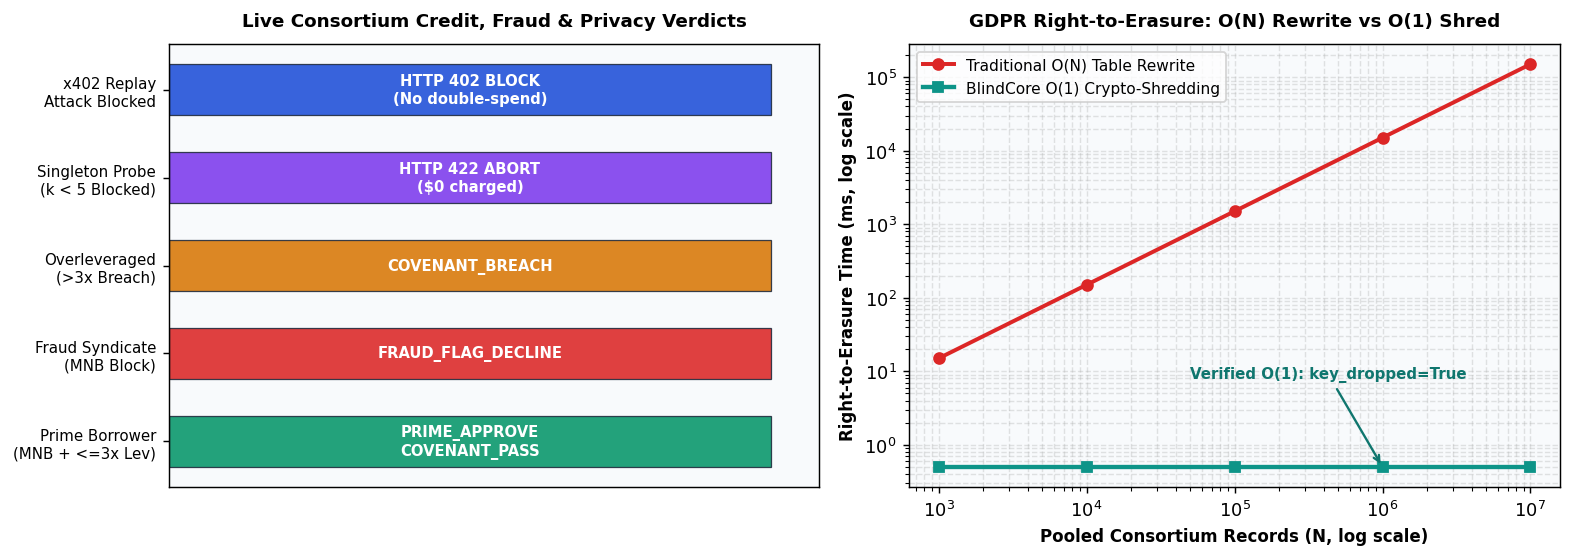

  GRANT & INVESTOR VERIFICATION BADGE : [ PASS ]
  Notebook 03 - Consortium Fraud & Confidential Credit (Base x402 v2)
  Live Testnet 402: HTTP 402 | k_min_tkms Guard: HTTP 422 | O(1) Shred: True
  EIP-712 Digest  : 0x2a36ccfeeb7fbbd3a0251196bb6894ece897014717ae37167e3b7b2c7e7869a9


In [3]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.4), dpi=130)
fig.patch.set_facecolor("white")

# Panel A: Live Consortium Underwriting & Privacy Guard Verdicts
checks = [
    "Prime Borrower\n(MNB + <=3x Lev)",
    "Fraud Syndicate\n(MNB Block)",
    "Overleveraged\n(>3x Breach)",
    "Singleton Probe\n(k < 5 Blocked)",
    "x402 Replay\nAttack Blocked",
]
status_codes = [200, 200, 200, kguard["singleton_http_status"], sm["x402_replay_http_status"]]
verdict_labels = [
    f"{mnb['prime_rwa_borrower']}\n{cov['prime_cohort_verdict']}",
    mnb["high_risk_syndicate"],
    cov["overleveraged_cohort_verdict"],
    f"HTTP {kguard['singleton_http_status']} ABORT\n($0 charged)",
    f"HTTP {sm['x402_replay_http_status']} BLOCK\n(No double-spend)",
]
colors_a = ["#059669", "#DC2626", "#D97706", "#7C3AED", "#1D4ED8"]
y = np.arange(len(checks))
ax1.barh(y, [100] * len(checks), color=colors_a, height=0.58, alpha=0.88, edgecolor="#1E293B", linewidth=0.7)
ax1.set_yticks(y)
ax1.set_yticklabels(checks, fontsize=8.3)
ax1.set_xlim(0, 108)
ax1.set_xticks([])
ax1.set_title("Live Consortium Credit, Fraud & Privacy Verdicts", fontsize=10.2, fontweight="bold", pad=10)
ax1.set_facecolor("#F8FAFC")
for yi, lbl in zip(y, verdict_labels):
    ax1.text(50, yi, lbl, ha="center", va="center", color="white", fontsize=8.2, fontweight="bold")

# Panel B: GDPR Erasure Scaling - Traditional O(N) Table Rewrite vs BlindCore O(1) Crypto-Shredding
corpus_rows = np.array([1_000, 10_000, 100_000, 1_000_000, 10_000_000])
trad_rewrite_ms = corpus_rows * 0.015  # illustrative O(N) encrypted table rewrite
blindcore_shred_ms = np.full_like(corpus_rows, 0.5, dtype=float)  # O(1) single-key drop
ax2.plot(corpus_rows, trad_rewrite_ms, marker="o", linewidth=2.2, color="#DC2626", label="Traditional O(N) Table Rewrite")
ax2.plot(corpus_rows, blindcore_shred_ms, marker="s", linewidth=2.4, color="#0D9488", label="BlindCore O(1) Crypto-Shredding")
ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_xlabel("Pooled Consortium Records (N, log scale)", fontsize=9.2, fontweight="bold")
ax2.set_ylabel("Right-to-Erasure Time (ms, log scale)", fontsize=9.2, fontweight="bold")
ax2.set_title("GDPR Right-to-Erasure: O(N) Rewrite vs O(1) Shred", fontsize=10.2, fontweight="bold", pad=10)
ax2.grid(True, which="both", linestyle="--", alpha=0.35)
ax2.legend(loc="upper left", fontsize=8.5, frameon=True)
ax2.set_facecolor("#F8FAFC")
ax2.annotate(
    f"Verified O(1): key_dropped={shred['key_dropped']}",
    xy=(1_000_000, 0.5),
    xytext=(50_000, 8.0),
    arrowprops=dict(arrowstyle="->", color="#0F766E", lw=1.3),
    fontsize=8.3,
    fontweight="bold",
    color="#0F766E",
)

import io
from IPython.display import Image, display

plt.tight_layout()
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=130, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(data=buf.getvalue()))

print("==========================================================================")
print("  GRANT & INVESTOR VERIFICATION BADGE : [ PASS ]")
print("  Notebook 03 - Consortium Fraud & Confidential Credit (Base x402 v2)")
print(f"  Live Testnet 402: HTTP {probe_status} | k_min_tkms Guard: HTTP {kguard['singleton_http_status']} | O(1) Shred: {shred['ciphertext_undecryptable']}")
print(f"  EIP-712 Digest  : {sp['digest']}")
print("==========================================================================")
